In [6]:
#STEP 1:- Data import

In [7]:
#import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


In [8]:
#import database/data
con = sqlite3.connect(r"E:\Complete Data Analytics Portfolio Project\customer_churn.db")

#Get all table names
sql_query="""
    SELECT name 
    FROM sqlite_master
    WHERE type='table'
"""

tables=pd.read_sql(sql_query, con)

#Create a DataFrame for each table 
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}",con)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe: df_{table_name}")
con.close()


Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [9]:
#prints every table name and its column names from your SQLite database
con=sqlite3.connect(r"E:\Complete Data Analytics Portfolio Project\customer_churn.db")

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    #PRAGMA table_info():- Get column information 
    column_query=f"PRAGMA table_info({table_name});"
    #Read the column information into Pandas
    columns=pd.read_sql(column_query,con)
    print("Columns:")
    print(columns['name'].tolist())
con.close()



Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [10]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [11]:
#df_db_subscription.head()

In [12]:
# to get idea use head and tail
#df_db_support.head()
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,col_1,comment
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None
5,0017-IUDMW,2024-04-10 00:00:00,Y,25,None,None
6,0019-EFAEP,2024-09-27 00:00:00,Y,30,None,None
7,0022-TCJCI,2024-09-13 00:00:00,Y,10,None,None
8,0022-TCJCI,2024-09-14 00:00:00,N,90,None,received refund


In [13]:
#step 2:- Data Cleaning


In [14]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [15]:
#a. rename column for more clear understanding
#b. drop column - intersect and pincode bcz pincode is empty and intertest is useless
#c. change dtype bcz it is obj and we req date
#d. data stanadardization - gender bcz men, male these type are present
#e. fix missing values- country

In [16]:
# A:- Remane col- name
df_db_customer.rename(columns={'name': 'customer_name'}, inplace=True)

In [17]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [18]:
# B. drop col - interest & pincode
#axis 1 for col
#df_db_customer.drop(df_db_customer.columns[-2:], axis=1) Or
#df_db_customer.drop(df_db_customer.columns[6:], axis=1) Or
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)

In [19]:
# C:- chnage data type dob
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [20]:
# D:- data stanardization- gender`
df_db_customer['gender'].unique()

array(['Male', 'Female', 'Women', 'Men'], dtype=object)

In [21]:
df_db_customer['gender'].replace({'Men':"Male", 'Women': 'Female'})

0       Male
1       Male
2     Female
3       Male
4     Female
5     Female
6     Female
7       Male
8     Female
9       Male
10      Male
11    Female
12    Female
13    Female
14      Male
15    Female
16    Female
17    Female
18      Male
19      Male
20    Female
Name: gender, dtype: object

In [22]:
# E:- fix missing value- country
df_db_customer['country'].isna() #where null

0     False
1     False
2     False
3     False
4     False
5      True
6     False
7     False
8      True
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
Name: country, dtype: bool

In [23]:
#In which rows
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Women,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Women,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [24]:
#using prev data to fill null value using mapping
#country and state - Unique value pair

state_country_mapping=df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [25]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [26]:
# Now move to table 2 i.e.. df_db_subscription 

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [28]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [29]:
date_col=['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col]=df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [30]:
# Move to table 3: df_db_support

In [31]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [32]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [33]:
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [34]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 420.0+ bytes


In [35]:
#Step 3:- Feature Engineering

In [36]:
#add col (churn_flag) to know leaved or not
df_db_subscription['churn_flag']=np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [37]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [38]:
# we will merge all table using pandas to get 1 table

In [39]:
#first fix support table duplicates then merge
df=(df_db_subscription
    .merge(df_db_customer, on='customerid', how ='left')
    .merge(df_db_support, on='customerid', how ='left'))

In [40]:
df.shape


(23, 20)

In [41]:
#something went extra 2 row
df_db_subscription.shape

(21, 12)

In [42]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN


In [43]:
df_db_subscription['customerid'].nunique()

21

In [44]:
df_db_support['customerid'].nunique()

7

In [45]:
df_db_customer['customerid'].nunique()

21

In [46]:
df_db_customer['customerid'].size

21

In [47]:
df_db_support['customerid'].size

9

In [48]:
df_db_support


,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [49]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [50]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [51]:
df_db_support['customerid'].size

7

In [52]:
#merge dataframe
df=(df_db_subscription
    .merge(df_db_customer, on='customerid', how ='left')
    .merge(df_db_support, on='customerid', how ='left'))

In [53]:
df.shape

(21, 21)

In [54]:
df.to_csv('exported_churn_data.csv', index=False)

In [55]:
# Data Analysis

In [56]:
# 1. Churn Rate

In [57]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [58]:
#28 percent people churn
churn_rate=df['churn_flag'].mean()*100
print("Churn Rate=", round(churn_rate,2),"%")

Churn Rate= 28.57 %


In [59]:
# 2. retenion Rate

In [60]:
retenion_rate=100-churn_rate
print("Retenion rate=",round(retenion_rate,2),"%")

Retenion rate= 71.43 %


In [61]:
df.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN


In [62]:
# 3. Churn by Plan Type
churn_by_plan=df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_by_plan')
print(churn_by_plan)

  plan_type  churn_by_plan
0     Basic          60.00
1   Premium          14.29
2  Standard          22.22


In [63]:
# 4 a. Churn by State + sum(revenue) & count of users
# 4 b. Churn by subscription + sum(revenue) & count of users

In [64]:
churn_by_state=df.groupby('state')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')

In [65]:
churn_by_subsription_type=df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_type')

In [66]:
# 5. Avg Revenue Per User
arpu=df['monthly_charges'].mean().round(2)
print("Avg Revenue Per User=",arpu)

Avg Revenue Per User= 18.85


In [67]:
# 6. Avg Tenure: how manys they stay
# count of days users had used our service: cancellation date else current date
today=pd.Timestamp.today()

df['tenure_days']=np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date']-df['subscription_start_date']).dt.days,
    (today-df['subscription_start_date']).dt.days
)

avg_tenure=df['tenure_days'].mean()
print("Avg Tenure (days)=",round(avg_tenure),0)

Avg Tenure (days)= 1583 0


In [68]:
# 7. Revenue At Risk- revenue lost from churned users
revenue_at_risk=df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K')=",revenue_at_risk)

Revenue at Risk (Rs 'K')= 73.94


In [69]:
# 8 Esclation Rate: promblem not solved and become bigger one
escalations_rate=(df['escalations']=='Y').mean()*100
print("Escalations Rtae=", round(escalations_rate,2),"%")

df.head(2)

Escalations Rtae= 19.05 %


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN,2071.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0,1501.0


In [70]:
# 9 Avg  Complaint Per User
avg_complaints=df['complaint_count'].sum()/df['customerid'].nunique()
print("Avg  Complaint Per User=", round(avg_complaints,2))

Avg  Complaint Per User= 0.43


In [71]:
# 10 Correlation Escallation vs Churn
# is e scalations's user churn
df[['escalations', 'churn_flag']].dropna()



,escalations,churn_flag
1,Y,1
4,Y,1
5,N,0
6,N,1
11,Y,1
13,Y,1
18,N,1


In [72]:
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)

corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])

print("Correlation between escaltion :", round(correlation, 2))

Correlation between escaltion : 0.77


In [73]:
print(corr_df['escalations'].value_counts())
print(corr_df['churn_flag'].value_counts())

print(corr_df.nunique())
print(corr_df.isnull().sum())

escalations
0    17
1     4
Name: count, dtype: int64
churn_flag
0    15
1     6
Name: count, dtype: int64
escalations    2
churn_flag     2
dtype: int64
escalations    0
churn_flag     0
dtype: int64


In [74]:
# 11 churn risk:- create a new column using existing col
conditions=[
    (df['churn_score']<50),
    (df['churn_score']>=50)& (df['churn_score']<70),
    (df['churn_score']>=70)
    
]

choices=['low', 'mid', 'high']

df['churn_risk']=np.select(conditions, choices, default='unkown')

In [75]:
df[['churn_risk','churn_score']].tail()

,churn_risk,churn_score
16,mid,62
17,low,27
18,high,99
19,low,7
20,low,47


In [76]:
# 4. Data Visualisation using matplotlib

In [77]:
df_visual=df.copy()

In [78]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='object')

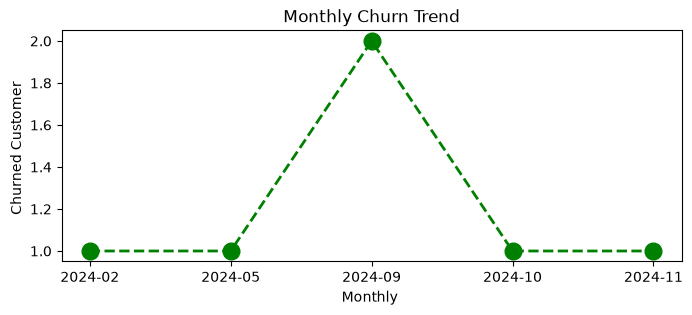

In [86]:
# 4.1 Monthly Churn Tren ( Time Series KPI )

df_visual['cancellation_month']=df_visual['cancellation_date'].dt.to_period('M')

#churn tren
churn_trend=df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype('str'),churn_trend.values,color='green' ,marker='o', linestyle='dashed',linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Monthly ')
plt.ylabel('Churned Customer ')
plt.show()


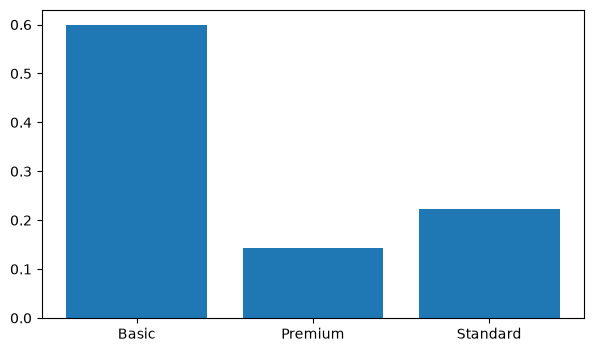

In [92]:
# 4.2 Churn by Plan type
churn_plan=df_visual.groupby('plan_type')['churn_flag'].mean()

plt.figure(figsize=(7,4))

plt.bar(churn_plan.index, churn_plan.values)
plt.show()

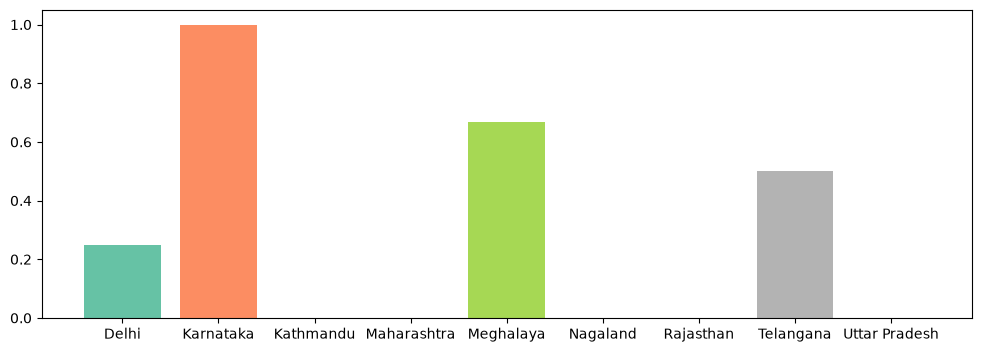

In [95]:
# 4.3 Churn by States

churn_plan=df_visual.groupby('state')['churn_flag'].mean()

# %colors
colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(12,4))

plt.bar(churn_plan.index, churn_plan.values, color=colors)
plt.show()

In [99]:
# Visualisation using Seaborn

In [100]:
# encoding - convert string to numeric so that we can find corr between features 
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [105]:
df_visual[['plan_type','contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [109]:
import warnings
warnings.filterwarnings("ignore")

In [110]:
# incorrect method of encoding - as number are not assigned based on priority
df_encoded=df_visual[['plan_type','contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']]

categorial_cols=['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col]=df_encoded[col].astype('category').cat.codes

In [111]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


<Axes: >

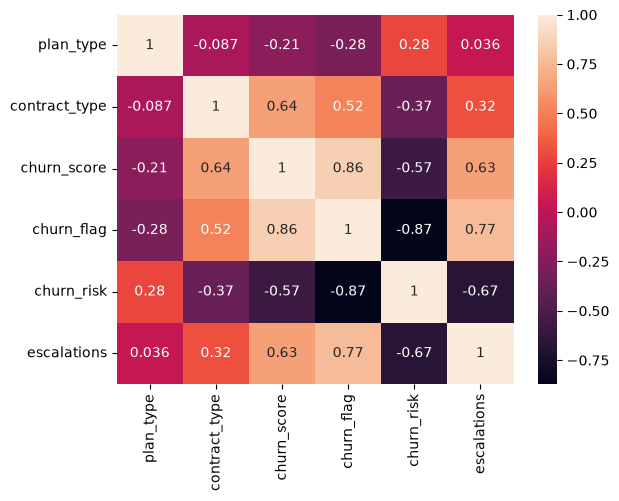

In [113]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [117]:
# correct method of encoding - as number are based on priority
df_encoded=df_visual[['plan_type','contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']]

order_mappings={
    'plan_type': ["Basic", 'Standard', 'Premium'],
    'contract_type':['Monthly', 'Annual'],
    'churn_risk':['low','med', 'high']
}

for col, order in order_mappings.items():
    df_encoded[col]=pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [118]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

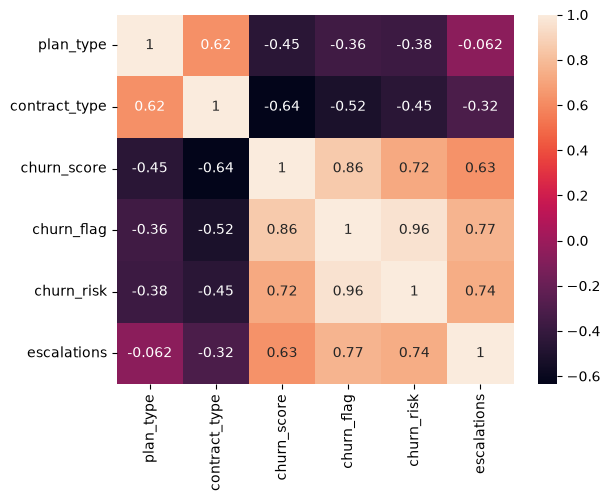

In [119]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

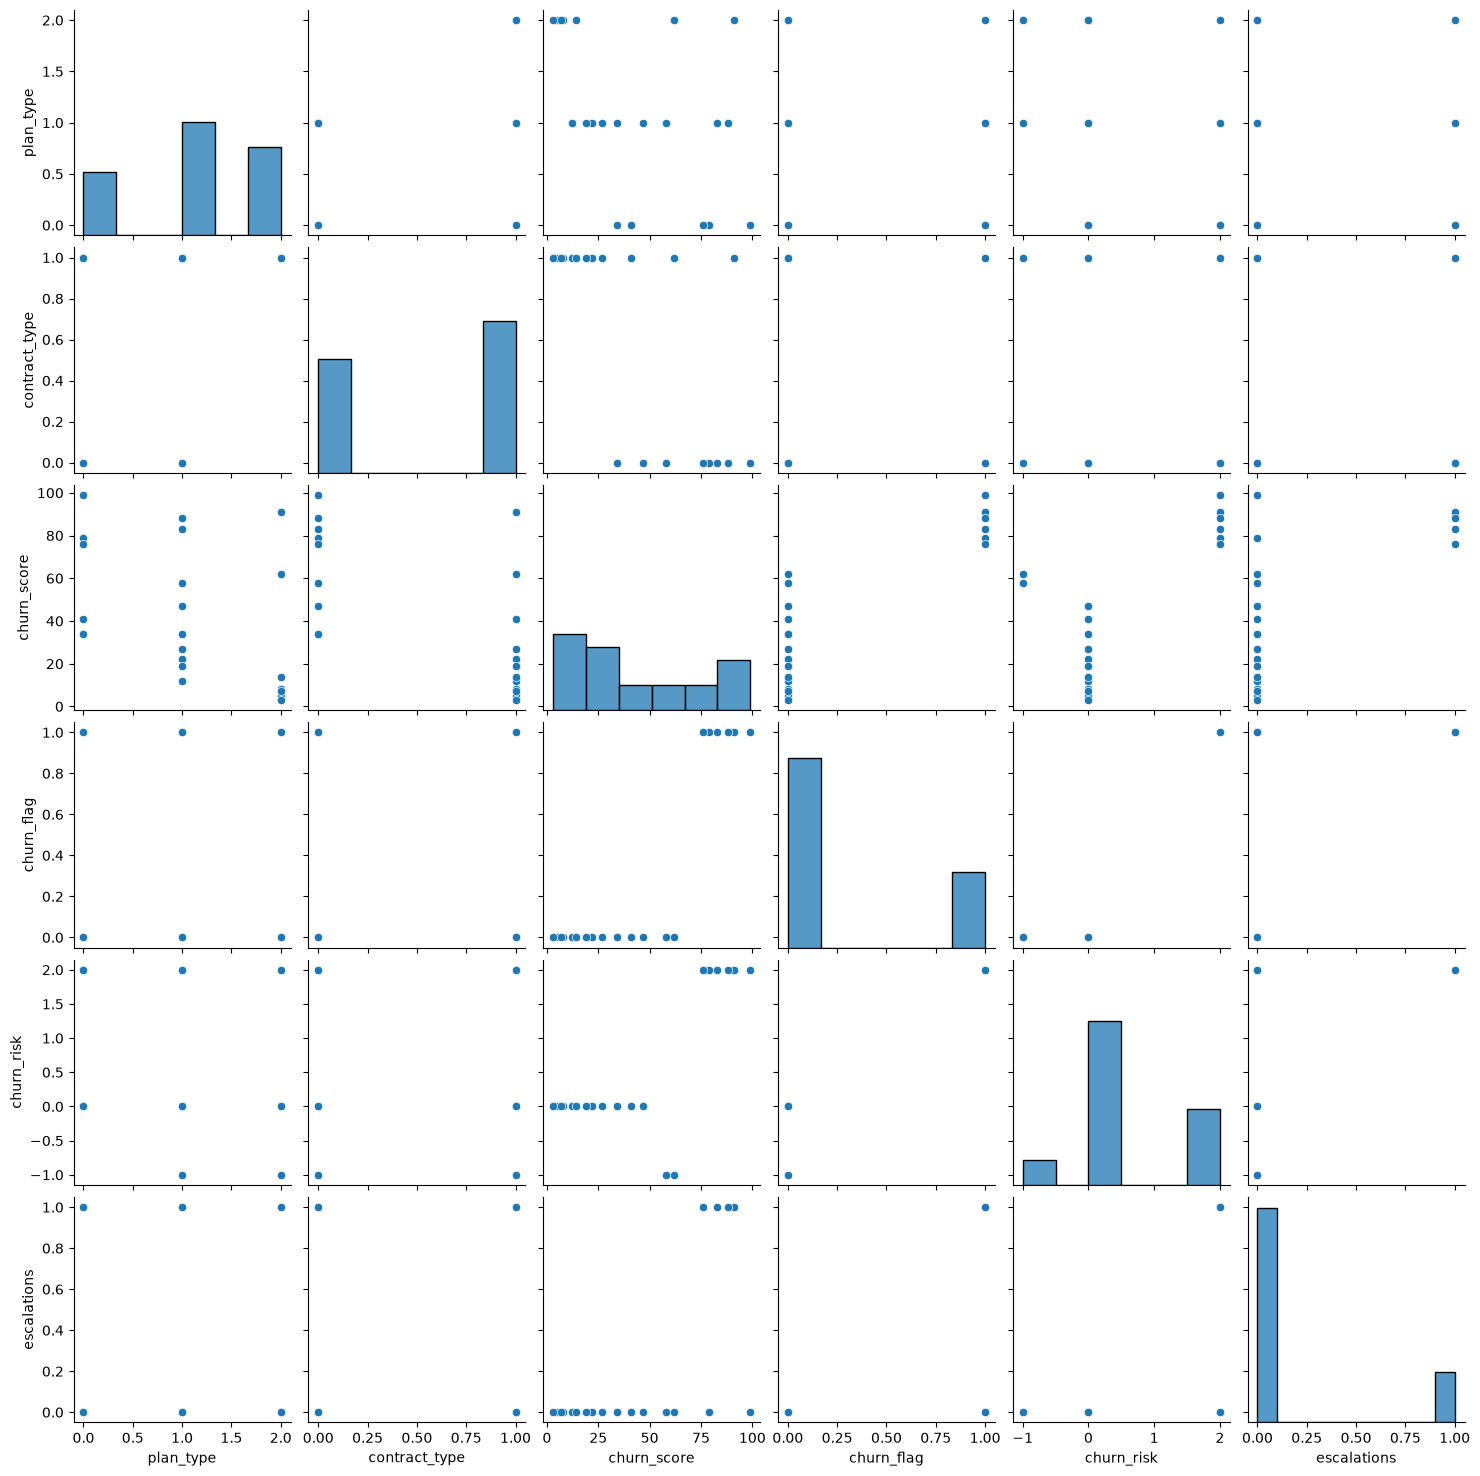

In [120]:
# Pairplot: show mult charts
sns.pairplot(df_encoded)

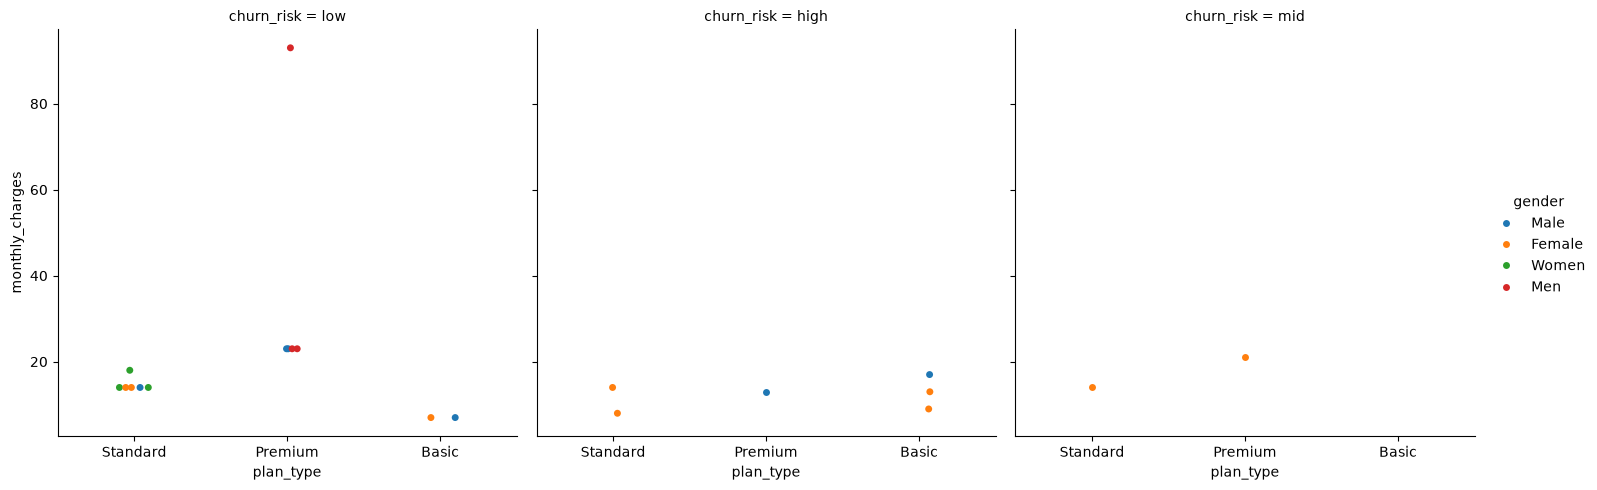

In [123]:
#catplot/Facegrid plot-multi-dim comparison

sns.catplot(data=df_visual,
           x='plan_type',
           y='monthly_charges',
           hue='gender',
           col='churn_risk',)

In [124]:
# Pivot Table

In [126]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc='mean',
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [127]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [128]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={
    'monthly_charges':'sum',
    'customerid':'nunique',
    'churn_flag':'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [129]:
# Working with SQL in Python (pandas)

In [135]:
# create database in sql
conn=sqlite3.connect('test_database.sqlite')

#table details
conn.execute("CREATE TABLE users (first_name TEXT, country TEXT, budget INTEGER)")

#commit and save
conn.commit()

In [141]:
# insert data

cursor=conn.cursor()

#write sql quey to insert records in sql table
cursor.execute(
    """
        INSERT INTO users VALUES
            ('Madhav', 'India', 5000),
            ('Rishabh', 'Germany', 2500),
            ('Vishakha', 'India', 3500)
    """
)

conn.commit()
print("Data Inserted successfully")

Data Inserted successfully


In [142]:
# check inserted data in ttable
conn=sqlite3.connect('test_database.sqlite')
query=""" SELECT * FROM users"""

df_results=pd.read_sql(query,conn)
df_results.head()

,first_name,country,budget
0,Madhav,india,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500
3,Madhav,india,5000
4,Rishabh,Germany,2500


In [144]:
# aggregation
query="""
    SELECT country, sum(budget) as total_budget
    FROM users
    GROUP BY country
"""
df_agg=pd.read_sql(query,conn)
df_agg

,country,total_budget
0,Germany,7500
1,India,15500
2,india,10000


In [146]:
#always close the conn with db once task is performed
conn.close()

# Insight

Insights
· Churn Rate: 28.6% | Retention Rate: 71.4%
. Most of the churn is from basic subscription plan - nothing to worry in terms of major revenue impact
. Most of the churn happened in the month of Sep 2024 and, most affected state is Karnataka
. Average Tenure (Days): 1,451 | ARPU is Rs 18.8
. Total Revenue = 395
. Revenue loss due to churn = 74 | CLTV Lost = 2,047
· % Revenue loss = 18%
. monthly vs annual churn = 55.6% vs 8.3%

Action Items
. Check what happened in Karnataka - was there any increase in price, user complaints, tech issues, etc
. Did we increabed subs price for Basic plan or recently made any changes - specially in sep month?
. Check what competitor is doing - bcoz one user has moved to competitor
. Focus on customers with 'High' & 'Med' churn risk, check their LTV (to make priority list), complaint request, reach out to
them through email, sms, calls and fix their issue.